# Comparison of different DEMs

In [ ]:
"""
File Name: compare_utm.ipynb

Author:
    Alessio Morea
    B-Open Solutions srl

Date: August 2025

Description:
------------
The primary function of this notebook is to perform a comparative analysis between two NRB datasets
of the same geographic area that were captured from different satellite viewing geometries (e.g., ascending and descending orbits).
It calculates the Root Mean Square Deviation (RMSD) of the Gamma Naught backscatter values.
The RMSD is calculated using two different DEMs:
    - COPDEM-10
    - COPDEM-30
Usage:
------
To use this script, you must provide the file paths for the two NRB products of each software you wish to compare.

"""

In [1]:
import rosel.io
import xarray as xr
import numpy as np
import scipy.ndimage

In [25]:
def rmsd_db(x, y):
    r = (10 * (np.log10(x) - np.log10(y))).values
    ind = np.where(np.isfinite(r))
    r = r[ind]
    mean = np.mean(r)
    std = np.std(r)
    rm = np.sqrt(np.sum(r**2) / r.size)
    return (r, mean, std, rm)


def rmsd(x, y):
    r = (x - y).values
    ind = np.where(np.isfinite(r))
    r = r[ind]
    mean = np.mean(r)
    std = np.std(r)

    rm = np.sqrt(np.sum(r**2) / r.size)
    return (r, mean, std, rm)


def compute_rmsd_spacing(s1, s2, n1, n2, coarsen_steps):
    res = s1.rio.resolution()
    if res[0] > 0:
        x1 = np.maximum(s1.x[0], s2.x[0]).values
        x2 = np.minimum(s1.x[-1], s2.x[-1]).values
    else:
        x1 = np.minimum(s1.x[0], s2.x[0]).values
        x2 = np.maximum(s1.x[-1], s2.x[-1]).values
    if res[1] < 0:
        y1 = np.minimum(s1.y[0], s2.y[0]).values
        y2 = np.maximum(s1.y[-1], s2.y[-1]).values
    else:
        y1 = np.maximum(s1.y[0], s2.y[0]).values
        y2 = np.minimum(s1.y[-1], s2.y[-1]).values
    sel_1 = s1.sel(
        x=slice(x1 - res[0] / 2, x2 + res[0] / 2),
        y=slice(y1 - res[1] / 2, y2 + res[1] / 2),
    ).chunk(1024)
    n_sel_1 = n1.sel(
        x=slice(x1 - res[0] / 2, x2 + res[0] / 2),
        y=slice(y1 - res[1] / 2, y2 + res[1] / 2),
    ).chunk(1024)
    sel_2 = s2.sel(
        x=slice(x1 - res[0] / 2, x2 + res[0] / 2),
        y=slice(y1 - res[1] / 2, y2 + res[1] / 2),
    ).chunk(1024)
    n_sel_2 = n2.sel(
        x=slice(x1 - res[0] / 2, x2 + res[0] / 2),
        y=slice(y1 - res[1] / 2, y2 + res[1] / 2),
    ).chunk(1024)
    print("resolution:", res)
    print("x_size", sel_1.x.size, sel_1.y.size)
    print("x_size", sel_2.x.size, sel_2.y.size)
    print("x1:", sel_1.x.values)
    print("x2:", sel_2.x.values)
    print("y1:", sel_1.y.values)
    print("y2:", sel_2.y.values)
    sel_2["x"] = sel_1.x.values
    sel_2["y"] = sel_1.y.values
    n_sel_2["x"] = n_sel_1.x.values
    n_sel_2["y"] = n_sel_1.y.values
    mask = (np.isfinite(sel_1) * (sel_1 > 1e-5)) * (
        np.isfinite(sel_2) * (sel_2 > 1e-5)
    ).values
    mask = xr.DataArray(
        scipy.ndimage.binary_erosion(
            mask, scipy.ndimage.generate_binary_structure(2, 2), iterations=2
        ),
        dims=["y", "x"],
        coords={"x": sel_1.x.values, "y": sel_1.y.values},
    )

    sel_1 = sel_1.where(mask, np.nan).persist()
    sel_2 = sel_2.where(mask, np.nan).persist()
    n_sel_1 = n_sel_1.where(mask, np.nan).persist()
    n_sel_2 = n_sel_2.where(mask, np.nan).persist()
    db_values = []
    db_rmsd = []
    lin_values = []
    lin_rmsd = []
    for i in coarsen_steps:
        print("_" * 50)
        print(i)
        c1 = (
            (sel_1 * n_sel_1).coarsen(x=i, y=i, boundary="trim").sum()
            / ((n_sel_1).coarsen(x=i, y=i, boundary="trim").sum())
        ).compute()
        c2 = (
            (sel_2 * n_sel_2).coarsen(x=i, y=i, boundary="trim").sum()
            / ((n_sel_2).coarsen(x=i, y=i, boundary="trim").sum())
        ).compute()

        r, mean, std, rm = rmsd_db(c1, c2)
        print(f"DB: {mean:.4f} +- {std:.4f}")
        db_values.append(r)
        db_rmsd.append(rm)

        r, mean, std, rm = rmsd(c1, c2)
        print(f"LIN: {mean:.4f} +- {std:.4f}")
        lin_values.append(r)
        lin_rmsd.append(rm)
    return db_values, db_rmsd, lin_values, lin_rmsd


def align(s1, s2, step):
    x1 = np.maximum(s1.x[0], s2.x[0]).values
    x2 = np.minimum(s1.x[-1], s2.x[-1]).values

    y1 = np.minimum(s1.y[0], s2.y[0]).values
    y2 = np.maximum(s1.y[-1], s2.y[-1]).values

    s1 = s1.sel(
        x=slice(x1 - step / 2, x2 + step / 2), y=slice(y1 + step / 2, y2 - step / 2)
    ).chunk(1024)
    s2 = s2.sel(
        x=slice(x1 - step / 2, x2 + step / 2), y=slice(y1 + step / 2, y2 - step / 2)
    ).chunk(1024)
    s2["x"] = s1.x.values
    s2["y"] = s1.y.values
    mask = (np.isfinite(s1) * np.isfinite(s2)).compute()
    s1 = s1.where(mask, np.nan)
    s2 = s2.where(mask, np.nan)
    return (s1, s2)

In [5]:
data_path_44_10m = "/home/morea/UTM/044/nrb_10m"
data_path_44_30m = "/home/morea/UTM/044/nrb_30m"
data_path_95_10m = "/home/morea/UTM/095/nrb_10m"
data_path_95_30m = "/home/morea/UTM/095/nrb_30m"

In [8]:
data_44_10m = rosel.io.read(
    f"{data_path_44_10m}",
    consolidate_metadata=False,
    mask_and_scale=False,
)
data_44_30m = rosel.io.read(
    f"{data_path_44_30m}",
    consolidate_metadata=False,
    mask_and_scale=False,
)
data_95_10m = rosel.io.read(
    f"{data_path_95_10m}",
    consolidate_metadata=False,
    mask_and_scale=False,
)
data_95_30m = rosel.io.read(
    f"{data_path_95_30m}",
    consolidate_metadata=False,
    mask_and_scale=False,
)

In [7]:
data = [
    ("44", "10", data_44_10m),
    ("44", "30", data_44_30m),
    ("95", "10", data_95_10m),
    ("95", "30", data_95_30m),
]

In [ ]:
nrbs = {"10": [], "30": []}
nl = {"10": [], "30": []}
for id, spacing, da in data:
    list_nrbs = []
    list_nlooks = []
    print("_" * 50)
    print(id, spacing)
    mask = (da.mask == 0).compute()
    a = da.gamma0.squeeze().where(mask, np.nan)
    b = da.nlooks.squeeze().where(mask, np.nan)
    nrbs[spacing].append(a)
    nl[spacing].append(b)

__________________________________________________
44 10
__________________________________________________
44 30
__________________________________________________
95 10
__________________________________________________
95 30


In [18]:
coarsen_steps = [1, 2, 4, 6, 8, 10, 15, 20, 30, 40, 50]

In [26]:
result_lin = {"V:H": {}, "V:V": {}}
result_db = {"V:H": {}, "V:V": {}}
for k, v in nrbs.items():
    print("=" * 50)
    print(k)
    for pol in ["V:H", "V:V"]:
        s1 = v[0].sel(polarization=pol).squeeze()
        s2 = v[1].sel(polarization=pol).squeeze()
        n1 = nl[k][0]
        n2 = nl[k][1]
        v_db, r_db, v_lin, r_lin = compute_rmsd_spacing(s1, s2, n1, n2, coarsen_steps)
        result_lin[pol][k] = r_lin
        result_db[pol][k] = r_db

__________________________________________________
10
resolution: (10.0, 10.0)
x_size 26330 15462
x_size 26330 15462
x1: [214005. 214015. 214025. ... 477275. 477285. 477295.]
x2: [214005. 214015. 214025. ... 477275. 477285. 477295.]
y1: [5176965. 5176975. 5176985. ... 5331555. 5331565. 5331575.]
y2: [5176965. 5176975. 5176985. ... 5331555. 5331565. 5331575.]
__________________________________________________
1
DB: -0.1471 +- 5.4303
LIN: -0.0010 +- 0.3075
__________________________________________________
2
DB: -0.1176 +- 3.8831
LIN: -0.0010 +- 0.2777
__________________________________________________
4
DB: -0.0999 +- 2.9540
LIN: -0.0010 +- 0.1971
__________________________________________________
6
DB: -0.0946 +- 2.6263
LIN: -0.0010 +- 0.1381
__________________________________________________
8
DB: -0.0951 +- 2.4120
LIN: -0.0010 +- 0.1018
__________________________________________________
10
DB: -0.0942 +- 2.2459
LIN: -0.0011 +- 0.0864
__________________________________________________

In [27]:
import matplotlib.pyplot as plt

plt.rcParams.update({"font.size": 20})
plt.rcParams["lines.markersize"] = 12
plt.rcParams["font.family"] = "serif"
cmap = plt.get_cmap("tab10")
colors = [cmap(i) for i in range(cmap.N)]
markers = ["s", "^", "v", "s", "P", "*", "X", "d"]
ls = ["--", "-", "dotted", "-."]

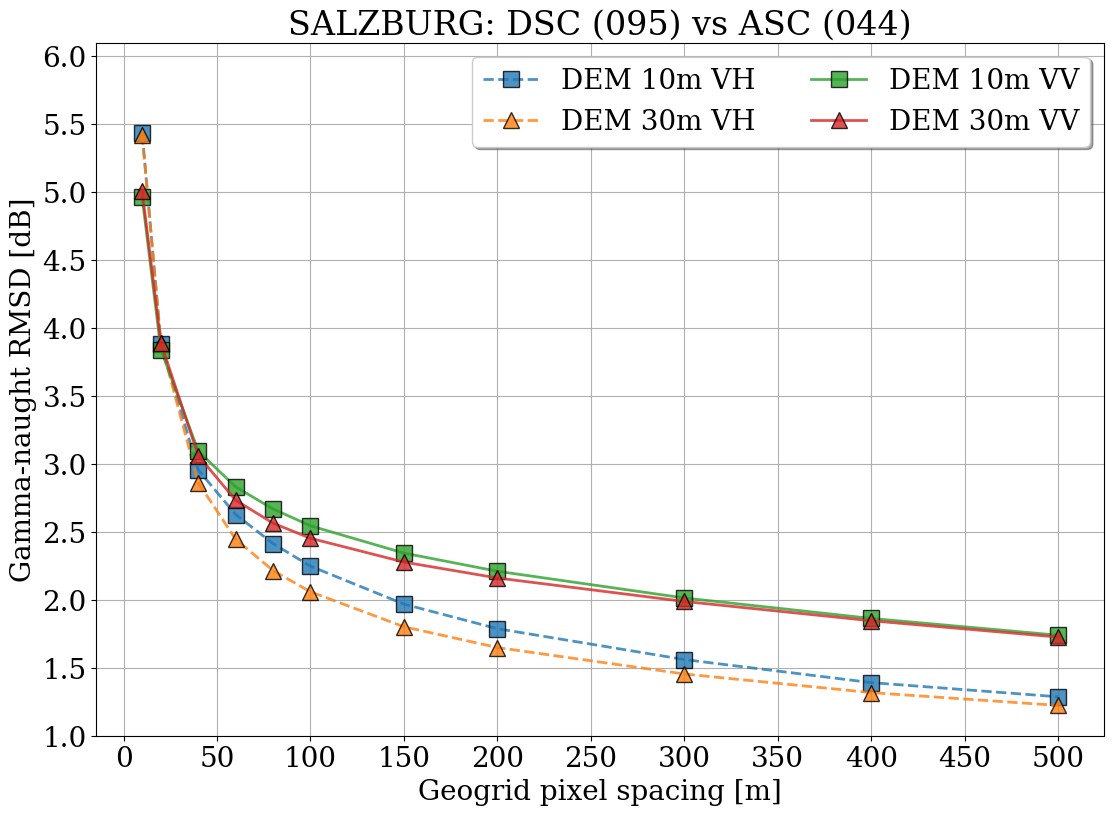

In [29]:
fig = plt.figure(figsize=(13, 9))
plt.title("SALZBURG: DSC (095) vs ASC (044)")
for h, pol in enumerate(["V:H", "V:V"]):
    for z, (s, v) in enumerate(result_db[pol].items()):
        plt.plot(
            np.array(coarsen_steps) * 10,
            v,
            marker=markers[z % len(markers)],
            ls=ls[h],
            color=colors[z + h * 2 % len(markers)],
            alpha=0.8,
            label=rf"DEM {s}m {''.join([pol[0],pol[2]])}",
            lw=2,
            mec="black",
        )
plt.xlabel("Geogrid pixel spacing [m]")
plt.ylabel("Gamma-naught RMSD [dB]")
plt.ylim(1, 6.1)
xticks = np.arange(0, 510, 50)
yticks = np.arange(1, 6.1, 0.5)
plt.xticks(xticks, labels=[f"{i:.0f}" for i in xticks])
plt.yticks(yticks, labels=[f"{i:.1f}" for i in yticks])
plt.grid()
plt.legend(loc="upper right", ncol=2, shadow=True)